# Overview: can any published half-life model be used on our data?

This notebook collects the results of every per-model notebook. It answers three
questions for all artifacts at once: how accurate they are on our human-serum cohort,
what they cost per peptide, and whether their accuracy survives the removal of peptides
they were trained on.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/model_benchmark").is_dir())
sys.path.insert(0, str(ROOT / "src"))

%matplotlib inline
import numpy as np
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
from model_benchmark import report
from model_benchmark.config import PRIMARY_COHORT
from model_benchmark.pipeline import load_summaries

summaries = load_summaries(cohort_name=PRIMARY_COHORT)
published = summaries.loc[summaries.configuration == "as published"]
variants = summaries.loc[summaries.configuration != "as published"]
print(f"Runs: {len(summaries)} ({len(published)} as published, {len(variants)} alternative configurations)")
print(f"Cohort: {summaries.cohort.unique()}")
if not variants.empty:
    print("Alternative configurations:", ", ".join(sorted(variants.configuration.unique())))

Runs: 13 (9 as published, 4 alternative configurations)
Cohort: <StringArray>
['human_serum_in_vitro']
Length: 1, dtype: str
Alternative configurations: deployed output convention, shipped scaler applied


## Accuracy

MAE is on the base-10 logarithmic scale; the median error factor is its plain reading.
The baseline column is the constant predictor that always answers the cohort median.

In [3]:
accuracy = report.accuracy_table(summaries)
display(accuracy.style.format(precision=3).set_caption("Point regression and duration classes, all runs"))

beats_baseline = accuracy["MAE log10"] < accuracy["MAE median baseline"]
beats_chance = accuracy["Spearman"].abs() > 0.2
print(f"Artifacts beating the median baseline: {int(beats_baseline.sum())} of {len(accuracy)}")
print(f"Artifacts ordering peptides better than chance: {int(beats_chance.sum())} of {len(accuracy)}")

,Run,Configuration,Representation,Target,Peptides,MAE log10,MAE median baseline,RMSE log10,R2,Spearman,Median error factor,Class accuracy,Majority class accuracy,Balanced class accuracy,Within measurement interval
0,peptiverse_transformer_esm_log,as published,facebook/esm2_t33_650M_UR50D (sequence),log1p,128,0.650,0.676,0.815,0.004,0.300,3.837,0.445,0.430,0.385,0.227
1,peptiverse_transformer_esm_log__deployed,deployed output convention,facebook/esm2_t33_650M_UR50D (sequence),log1p,128,0.704,0.676,0.870,-0.136,0.300,4.066,0.391,0.430,0.360,0.211
2,peptiverse_xgb_esm_raw__scaler,shipped scaler applied,facebook/esm2_t33_650M_UR50D (sequence),raw,128,0.684,0.676,0.904,-0.226,0.292,3.486,0.477,0.430,0.459,0.289
3,peptiverse_xgb_esm_log__scaler,shipped scaler applied,facebook/esm2_t33_650M_UR50D (sequence),log1p,128,0.668,0.676,0.837,-0.051,0.251,2.911,0.469,0.430,0.444,0.258
4,plifepred_svm,as published,amino-acid and dipeptide composition with molecular descriptors,nan,128,0.884,0.676,1.115,-0.864,0.222,5.505,0.320,0.430,0.346,0.164
5,peptiverse_transformer_esm_raw,as published,facebook/esm2_t33_650M_UR50D (sequence),raw,128,0.656,0.676,0.806,0.026,0.216,3.695,0.430,0.430,0.339,0.203
6,peptiverse_transformer_peptideclm,as published,aaronfeller/PeptideCLM-23M-all (smiles),raw,128,0.714,0.676,0.859,-0.106,0.144,4.306,0.398,0.430,0.323,0.148
7,peptiverse_xgb_chemberta,as published,DeepChem/ChemBERTa-77M-MLM (smiles),raw,128,0.697,0.676,0.848,-0.078,0.073,4.902,0.422,0.430,0.330,0.227
8,peptiverse_xgb_peptideclm,as published,aaronfeller/PeptideCLM-23M-all (smiles),raw,128,0.680,0.676,0.829,-0.031,0.056,5.015,0.430,0.430,0.333,0.203
9,peptiverse_xgb_esm_log,as published,facebook/esm2_t33_650M_UR50D (sequence),log1p,128,0.865,0.676,1.052,-0.659,0.031,4.460,0.312,0.430,0.345,0.062


Artifacts beating the median baseline: 3 of 13
Artifacts ordering peptides better than chance: 6 of 13


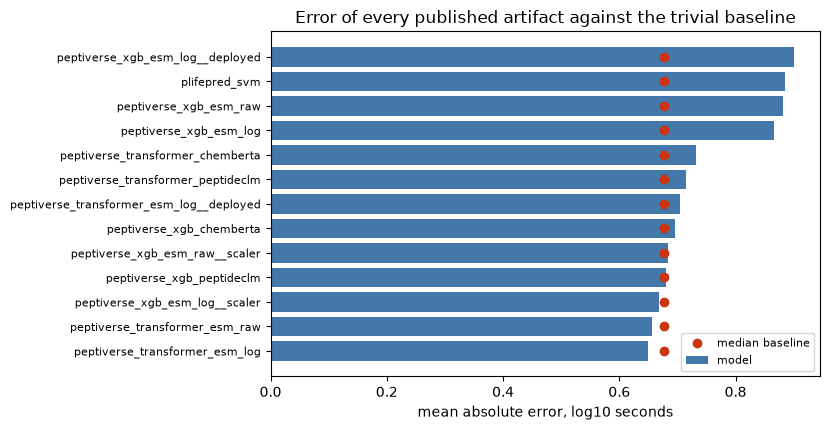

In [4]:
figure, axes = plt.subplots(figsize=(8.4, 4.4))
order = accuracy.sort_values("MAE log10")
positions = np.arange(len(order))
axes.barh(positions, order["MAE log10"], color="#4477AA", label="model")
axes.plot(order["MAE median baseline"], positions, "o", color="#CC3311", label="median baseline")
axes.set_yticks(positions, order["Run"], fontsize=8)
axes.set_xlabel("mean absolute error, log10 seconds")
axes.set_title("Error of every published artifact against the trivial baseline")
axes.legend(fontsize=8)
figure.tight_layout()
display(figure)
plt.close("all")

## Effect of training overlap

A published model evaluated on its own training peptides reports its fit. The held-out
columns are the only transfer estimate.

In [5]:
display(report.leakage_table(summaries).style.format(precision=3)
        .set_caption("Accuracy inside and outside the published training set"))

,Run,Configuration,Peptides in training set,Overlap share,MAE on overlap,Spearman on overlap,MAE held out,Spearman held out,R2 held out
0,peptiverse_transformer_chemberta,as published,26,0.203,0.728,0.189,0.733,-0.155,-0.200
1,peptiverse_transformer_esm_log,as published,26,0.203,0.622,0.222,0.657,0.307,-0.016
2,peptiverse_transformer_esm_log__deployed,deployed output convention,26,0.203,0.663,0.222,0.714,0.307,-0.182
3,peptiverse_transformer_esm_raw,as published,26,0.203,0.710,0.353,0.642,0.239,0.031
4,peptiverse_transformer_peptideclm,as published,26,0.203,0.671,0.117,0.725,0.092,-0.141
5,peptiverse_xgb_chemberta,as published,26,0.203,0.686,0.164,0.699,0.017,-0.111
6,peptiverse_xgb_esm_log,as published,26,0.203,0.809,-0.240,0.880,0.054,-0.710
7,peptiverse_xgb_esm_log__deployed,deployed output convention,26,0.203,0.836,-0.240,0.917,0.054,-0.848
8,peptiverse_xgb_esm_log__scaler,shipped scaler applied,26,0.203,0.541,0.322,0.701,0.141,-0.126
9,peptiverse_xgb_esm_raw,as published,26,0.203,0.982,-0.004,0.855,-0.027,-0.700


## Effect of the two defects found in the distributed artifacts

Two configurations differ from what the authors deploy. Applying the feature scaler that
ships beside the XGBoost artifacts, which their inference script never loads, and
reproducing their output convention, which omits the inverse of the `log1p` target
transform. The comparison below isolates how much each defect costs.

In [6]:
if not variants.empty:
    comparison = summaries[["artifact", "configuration", "mae_log10", "r2", "spearman_rho",
                            "accuracy", "interval_hit_rate"]]
    pivot = comparison.pivot_table(index="artifact", columns="configuration",
                                   values=["mae_log10", "spearman_rho", "accuracy"])
    display(pivot.style.format(precision=3).set_caption("Published configuration against the alternatives"))
    ## The rank correlation is invariant under the log1p convention, since the transform
    ## is monotone; the error and the class assignment are not.
    display(comparison.sort_values(["artifact", "configuration"]).style.format(precision=3)
            .set_caption("All runs, by artifact and configuration"))
else:
    print("No alternative-configuration runs stored; run scripts/run_variant_checks.py")

,artifact,configuration,mae_log10,r2,spearman_rho,accuracy,interval_hit_rate
0,peptiverse_transformer_chemberta,as published,0.732,-0.154,-0.085,0.422,0.180
1,peptiverse_transformer_esm_log,as published,0.650,0.004,0.300,0.445,0.227
2,peptiverse_transformer_esm_log,deployed output convention,0.704,-0.136,0.300,0.391,0.211
3,peptiverse_transformer_esm_raw,as published,0.656,0.026,0.216,0.430,0.203
4,peptiverse_transformer_peptideclm,as published,0.714,-0.106,0.144,0.398,0.148
5,peptiverse_xgb_chemberta,as published,0.697,-0.078,0.073,0.422,0.227
6,peptiverse_xgb_esm_log,as published,0.865,-0.659,0.031,0.312,0.062
7,peptiverse_xgb_esm_log,deployed output convention,0.900,-0.786,0.031,0.297,0.070
8,peptiverse_xgb_esm_log,shipped scaler applied,0.668,-0.051,0.251,0.469,0.258
9,peptiverse_xgb_esm_raw,as published,0.881,-0.739,0.011,0.320,0.227


## Numerical cost

Measured on this machine. The batching speed-up is the ratio between the published
per-peptide calling pattern and the batched path of this module.

,Run,Configuration,Device,s / peptide (one call),s / peptide (batched),Peptides / s (batched),Batching speed-up,Peak GPU MB,s / 1000 peptides
0,peptiverse_xgb_chemberta,as published,cuda,0.0060,0.0019,518.8269,3.1084,2968.9544,1.9274
1,peptiverse_transformer_chemberta,as published,cuda,0.0108,0.0030,334.3912,3.6078,2986.2477,2.9905
2,peptiverse_xgb_peptideclm,as published,cuda,0.0110,0.0073,137.6086,1.5083,3014.2346,7.2670
3,peptiverse_transformer_peptideclm,as published,cuda,0.0185,0.0077,129.8222,2.4005,3016.2191,7.7028
4,peptiverse_transformer_esm_raw,as published,cuda,0.0465,0.0126,79.0913,3.6781,2745.2989,12.6436
5,peptiverse_transformer_esm_log,as published,cuda,0.0492,0.0126,79.0575,3.8899,2736.7793,12.6490
6,peptiverse_xgb_esm_log,as published,cuda,0.0470,0.0127,78.6263,3.6964,2739.4796,12.7184
7,peptiverse_xgb_esm_raw,as published,cuda,0.0468,0.0127,78.4345,3.6682,2739.4796,12.7495
8,plifepred_svm,as published,nan,nan,nan,nan,nan,nan,nan


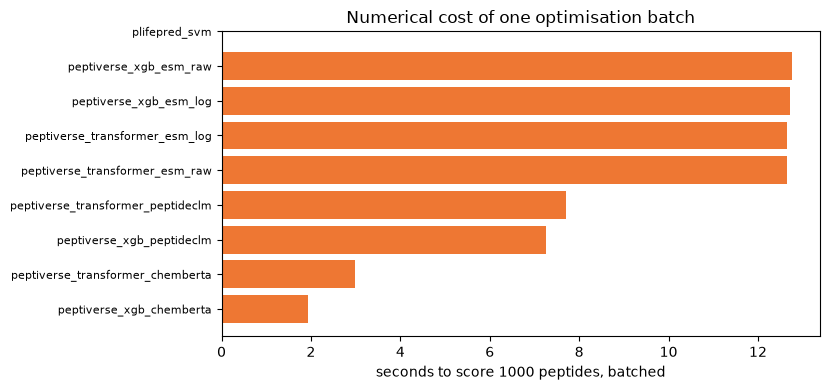

In [7]:
costs = report.cost_table(published)
display(costs.style.format(precision=4).set_caption("Cost per peptide and projected batch cost"))

figure, axes = plt.subplots(figsize=(8.4, 4.0))
order = costs.sort_values("s / 1000 peptides")
axes.barh(np.arange(len(order)), order["s / 1000 peptides"], color="#EE7733")
axes.set_yticks(np.arange(len(order)), order["Run"], fontsize=8)
axes.set_xlabel("seconds to score 1000 peptides, batched")
axes.set_title("Numerical cost of one optimisation batch")
figure.tight_layout()
display(figure)
plt.close("all")

## Sensitivity summary

The full analysis is in the sensitivity notebook; the table below is the comparison
across artifacts.

In [8]:
display(report.sensitivity_table(summaries).style.format(precision=4)
        .set_caption("Response to a single substitution, all artifacts"))

,Run,Configuration,Median |delta| substitution,Max |delta| substitution,Median |delta| permutation,Permutation / substitution,Positional variance share,Identical predictions,Gradient vs scan Spearman,Measured pairs,Sign agreement,Spearman of delta,Predicted / measured effect
0,peptiverse_transformer_chemberta,as published,0.0634,1.3996,0.1138,1.7961,0.2773,0.0000,nan,9.0000,0.5556,-0.2333,0.1992
1,peptiverse_transformer_esm_log,as published,0.1012,0.7239,0.1180,1.1661,0.4568,0.0000,0.3833,9.0000,0.6667,0.3000,0.1373
2,peptiverse_transformer_esm_log__deployed,deployed output convention,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
3,peptiverse_transformer_esm_raw,as published,0.1008,0.7915,0.1071,1.0628,0.3593,0.0000,0.3750,9.0000,0.4444,-0.1167,0.2688
4,peptiverse_transformer_peptideclm,as published,0.0541,0.5402,0.0832,1.5394,0.3622,0.0000,nan,9.0000,0.7778,0.5500,0.0755
5,peptiverse_xgb_chemberta,as published,0.0716,0.5792,0.0755,1.0538,0.2573,0.0000,nan,9.0000,0.3333,0.5000,0.1074
6,peptiverse_xgb_esm_log,as published,0.0485,0.3240,0.0473,0.9751,0.2642,0.0000,nan,9.0000,0.3333,-0.0667,0.1012
7,peptiverse_xgb_esm_log__deployed,deployed output convention,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
8,peptiverse_xgb_esm_log__scaler,shipped scaler applied,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
9,peptiverse_xgb_esm_raw,as published,0.0116,0.2239,0.0111,0.9571,0.1224,0.0000,nan,9.0000,0.4444,0.0833,0.0146


## Verdict per artifact

Threshold comparisons on the numbers above, generated from the stored results.

In [9]:
for run in summaries.run:
    stored = report.load_result(run, "summary.json", PRIMARY_COHORT)
    print(f"=== {run} ===")
    for line in report.verdict_lines(stored):
        print("  -", line)
    print()

=== peptiverse_transformer_chemberta ===
  - Does not order our peptides: Spearman -0.085, which is indistinguishable from chance.
  - Worse than answering the cohort median: MAE 0.732 against 0.676 log10 (factor 5.4 against 4.7), so it is not calibrated for our cohort.
  - Duration class accuracy 0.422, below the majority-class baseline 0.430.
  - Lands inside the estimated measurement interval for 18% of peptides.
  - 20% of the cohort appears in the published training set; on the held-out part Spearman is -0.155.
  - Reacts to a single substitution with median |delta| 0.063 log10 (factor 1.16).
  - Reordering produces 1.80 of the substitution response, so residue order carries at least as much of the response as the identity of the replaced residue.
  - On 9 measured single-substitution pairs the predicted direction agrees 56% of the time.
  - Predicted substitution effects are 0.20 times the measured ones (measured median 0.38 log10).

=== peptiverse_transformer_esm_log ===
  - Ord